# Exercise 3: PICMUS multi-angle compounding

## Question

What changes when one image is reconstructed from 75 plane-wave transmissions, and how much of repeated-run time is spent moving data versus beamforming and compounding it?

This notebook compares the same PICMUS UFF input through two ways of passing arrays to mach:

- **NumPy:** source arrays remain in host memory between calls and are staged to CuPy inside each reconstruction, so repeated HtoD copies are included in the measured call.
- **CuPy:** the input and geometry arrays are copied to the GPU once, then reused across reconstructions.

By default, the notebook analyzes the saved benchmark JSON, B-mode arrays, and Nsight traces, so it can run locally without a GPU. Set `RUN_BENCHMARKS = True` in the setup cell to repeat the GPU runs on a Colab T4.

## Connection to Exercise 2

Exercise 2 calls [`mach.kernel.beamform`](https://forest-neurotech.github.io/mach/generated/mach.kernel.beamform.html) for one transmit. Exercise 3 uses [`mach.experimental.beamform`](https://forest-neurotech.github.io/mach/generated/mach.experimental.beamform.html) for all 75 transmissions. In mach-beamform 0.2.1, `experimental.beamform` is a Python wrapper around that same kernel: it loops over transmissions and passes a shared output buffer to each `kernel.beamform` call. Each CUDA launch adds its transmit’s complex contribution to that buffer with `atomicAdd` on the real and imaginary components ([wrapper source](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/experimental.py#L46-L89), [CUDA accumulation](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/kernel.cu#L624-L632)).

So Exercise 3 compounds on the GPU during the 75 kernel calls; there is no separate post-kernel image-sum step. Its NumPy-versus-CuPy comparison measures input residency around that path: stage host arrays each reconstruction, or upload once and reuse device arrays.

## Scope and key questions

The selected PICMUS file contains **one pre-acquired frame** and **75 steered transmissions**. Each reconstruction coherently compounds those transmissions into one image on the native scan grid. This is a single-image reconstruction experiment; it does not run a slow-time sequence, clutter filter, or Power Doppler reduction.

The receive-element and scan coordinates are shared across the transmit angles. Angle-specific travel-time data is represented together in the **tx_wave_arrivals_s** array, whose leading dimension corresponds to the 75 transmissions. In CuPy mode, the benchmark converts the four input arrays to CuPy arrays once before warmup and reuses them.

Questions to answer:

1. Do NumPy-input and CuPy-input runs produce closely matching normalized images?
2. How do per-image p50/p95/p99 wall and CUDA-event timings compare?
3. What one-time UFF/setup and CuPy upload costs are reported separately?
4. Does Nsight show repeated HtoD transfers on the NumPy path and one initial upload on the CuPy path? Which kernels, copies, synchronization points, and gaps are visible?

A CUDA-event interval around a beamformer call measures work ordered on the CUDA stream between its events. It should not automatically be called pure kernel time: use the trace to check whether transfers also fall in that interval.


## Pipeline stages and what each timer covers

| Stage | NumPy mode | CuPy mode | Report or trace evidence |
|---|---|---|---|
| Dataset load and geometry setup | Download/cache UFF if needed, parse it, prepare arrays | Same | dataset_load_and_setup_ms_once |
| Initial input placement | Inputs start in host memory | Four arrays are copied to GPU once | input_upload_ms_once; setup/input_upload NVTX range |
| Warmup | Untimed reconstruction calls | Same, after initial upload | warmup/beamform/(numpy or cupy) NVTX ranges |
| Measured reconstruction | Four host arrays are staged to CuPy inside each call; inspect repeated HtoD transfers | Each call reuses resident CuPy arrays | coherent_compounding_wall_ms; beamform_device_event_ms; measure/beamform/(numpy or cupy) NVTX ranges |
| Final B-mode output | Convert final result to host if needed | Copy the final image to host | output_bmode_transfer_ms_last_run; output/bmode_d2h NVTX range |

The one-time load and upload values are not included in the repeated-call percentiles. Use the unprofiled report for timing comparisons; Nsight traces add overhead and locate activity.


## 1. Locate the checkout and choose a run mode

The default is local analysis from the saved results and artifacts. To collect a fresh benchmark and new traces, set `RUN_BENCHMARKS = True` in the setup cell and connect this notebook to the Colab T4. The repository is found by walking up from the notebook working directory.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

# False reuses the saved JSON, NumPy arrays, and Nsight traces locally.
# True requires a connected NVIDIA GPU runtime and reruns the benchmarks.
RUN_BENCHMARKS = False

_here = Path.cwd().resolve()
REPO_ROOT = next(
    (p for p in (_here, *_here.parents)
     if (p / "pyproject.toml").is_file()
     and (p / "src/beamforming_lab/picmus.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Open this notebook from within the realtime-beamforming-lab checkout. "
        "In Colab, clone or upload the current project first."
    )

os.chdir(REPO_ROOT)
ARTIFACTS = REPO_ROOT / "artifacts"
RESULTS = REPO_ROOT / "results"
ARTIFACTS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
print(f"Repository: {REPO_ROOT}")
print(f"Artifacts:  {ARTIFACTS}")
print(f"Results:    {RESULTS}")
print("Mode:", "fresh T4 benchmark and trace capture" if RUN_BENCHMARKS else "local analysis from saved artifacts")

Repository: /Users/vickgidwani/work/merge_study_guide/realtime-beamforming-lab
Artifacts:  /Users/vickgidwani/work/merge_study_guide/realtime-beamforming-lab/artifacts
Results:    /Users/vickgidwani/work/merge_study_guide/realtime-beamforming-lab/results
Mode: local analysis from saved artifacts


When `RUN_BENCHMARKS` is true, the next cell verifies the NVIDIA runtime and installs the Colab-compatible optional dependencies. The UFF file is downloaded and SHA-256 checked by the loader on first use; it is cached outside the repository.

In [2]:
if RUN_BENCHMARKS:
    gpu = subprocess.run(["nvidia-smi"], text=True, capture_output=True)
    print(gpu.stdout if gpu.returncode == 0 else gpu.stderr)
    if gpu.returncode != 0:
        raise RuntimeError("The active runtime does not expose nvidia-smi; select a GPU runtime.")

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-e", ".[gpu-colab]"],
        cwd=REPO_ROOT,
        check=True,
    )
else:
    print("Reusing saved reports and arrays; no GPU setup is needed for local analysis.")

Reusing saved reports and arrays; no GPU setup is needed for local analysis.


Local analysis needs NumPy and Matplotlib. CuPy is imported only for a fresh run on a GPU runtime; the saved reports already record the GPU and CUDA provenance.

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

if RUN_BENCHMARKS:
    import cupy as cp

    props = cp.cuda.runtime.getDeviceProperties(0)
    gpu_name = props["name"].decode() if isinstance(props["name"], bytes) else props["name"]
    print("GPU:", gpu_name)
    print("CuPy:", cp.__version__)
    print("CUDA runtime:", cp.cuda.runtime.runtimeGetVersion())
else:
    print("Local analysis kernel:", sys.executable)
    print("NumPy:", np.__version__)
    print("Matplotlib:", matplotlib.__version__)

Local analysis kernel: /Users/vickgidwani/miniconda3/envs/realtime-beamforming-ex2/bin/python
NumPy: 2.5.4
Matplotlib: 3.11.2


## 2. Load saved results or run matched GPU benchmarks

The saved reports were collected with two warmups and 20 measured reconstructions per mode. In local analysis mode, the notebook loads those JSON reports and B-mode arrays. In GPU mode, each benchmark is rerun and overwrites its corresponding saved files.

In [4]:
def run_benchmark(mode, runs=20, warmup=2):
    report_path = RESULTS / f"exercise3-picmus-{mode}.json"
    image_path = ARTIFACTS / f"exercise3-picmus-{mode}-bmode.npy"
    command = [
        "beamform-lab", "benchmark", "--dataset", "picmus",
        "--mode", mode, "--runs", str(runs), "--warmup", str(warmup),
        "--save-image", str(image_path), "--output", str(report_path),
    ]
    print("Running:", " ".join(command))
    subprocess.run(command, cwd=REPO_ROOT, check=True)
    return report_path, image_path

if RUN_BENCHMARKS:
    numpy_report_path, numpy_image_path = run_benchmark("numpy")
    cupy_report_path, cupy_image_path = run_benchmark("cupy")
else:
    numpy_report_path = RESULTS / "exercise3-picmus-numpy.json"
    cupy_report_path = RESULTS / "exercise3-picmus-cupy.json"
    numpy_image_path = ARTIFACTS / "exercise3-picmus-numpy-bmode.npy"
    cupy_image_path = ARTIFACTS / "exercise3-picmus-cupy-bmode.npy"
    required_files = [numpy_report_path, cupy_report_path, numpy_image_path, cupy_image_path]
    missing_files = [str(p) for p in required_files if not p.is_file()]
    if missing_files:
        raise FileNotFoundError("Saved Exercise 3 files are missing: " + ", ".join(missing_files))
    print("Loaded saved NumPy/CuPy benchmark reports and B-mode arrays.")

Loaded saved NumPy/CuPy benchmark reports and B-mode arrays.


## 3. Check workload metadata and image agreement

The report records the dataset fingerprint, runtime, scan dimensions, input-array shapes, dtypes, and byte sizes. The four input arrays total 399,829,932 bytes (399.83 MB). For CuPy, total input-array payload is the amount passed through the one-time upload loop. The angle-specific arrival array and channel data both include all 75 transmissions; scan and receive geometry are shared.

Image comparison normalizes each magnitude image by its own peak before computing relative L2 and maximum absolute differences. This checks spatial agreement without letting a small global gain difference dominate. Keep the measured errors alongside the plots; do not infer a universal numerical tolerance from one GPU/runtime pair.


In [5]:
import json

reports = {
    "numpy": json.loads(numpy_report_path.read_text()),
    "cupy": json.loads(cupy_report_path.read_text()),
}
images = {
    "numpy": np.load(numpy_image_path),
    "cupy": np.load(cupy_image_path),
}

for mode, report in reports.items():
    provenance = report["data_provenance"]
    print(f"{mode.upper()}: {report['runtime_provenance'].get('gpu')}")
    print("  dataset:", provenance["dataset_id"])
    print("  revision:", report["runtime_provenance"].get("git_revision"))
    print("  transmits / frames:", provenance["transmit_count"], "/", provenance["frame_count"])
    print("  scan grid:", report["scan_grid_shape_lateral_depth"])
    print("  input bytes:", provenance["beamform_input_bytes_total"])
    for name, spec in provenance["beamform_input_arrays"].items():
        print(f"    {name}: shape={spec['shape']}, dtype={spec['dtype']}, bytes={spec['nbytes']}")

assert images["numpy"].shape == images["cupy"].shape

def peak_normalize(image):
    image = np.asarray(image, dtype=np.float64)
    peak = np.max(np.abs(image))
    if peak == 0:
        return image
    return image / peak

numpy_norm = peak_normalize(images["numpy"])
cupy_norm = peak_normalize(images["cupy"])
difference = cupy_norm - numpy_norm
relative_l2 = np.linalg.norm(difference.ravel()) / max(np.linalg.norm(numpy_norm.ravel()), 1e-30)
max_abs_difference = np.max(np.abs(difference))
print(f"Normalized relative L2 error: {relative_l2:.6g}")
print(f"Normalized max absolute error: {max_abs_difference:.6g}")
print("Image shape:", images["numpy"].shape)


NUMPY: {'name': 'Tesla T4', 'compute_capability': '7.5', 'memory_bytes': 15637086208, 'driver_version': '13.0', 'runtime_version': '13.0'}
  dataset: PICMUS_experiment_resolution_distortion.uff
  revision: fe85819c26920256b37a5323140831d29823857f
  transmits / frames: 75 / 1
  scan grid: [387, 609]
  input bytes: 399829932
    channel_data: shape=[75, 128, 3328, 1], dtype=complex64, bytes=255590400
    rx_coords_m: shape=[128, 3], dtype=float32, bytes=1536
    scan_coords_m: shape=[235683, 3], dtype=float32, bytes=2828196
    tx_wave_arrivals_s: shape=[75, 235683], dtype=float64, bytes=141409800
CUPY: {'name': 'Tesla T4', 'compute_capability': '7.5', 'memory_bytes': 15637086208, 'driver_version': '13.0', 'runtime_version': '13.0'}
  dataset: PICMUS_experiment_resolution_distortion.uff
  revision: fe85819c26920256b37a5323140831d29823857f
  transmits / frames: 75 / 1
  scan grid: [387, 609]
  input bytes: 399829932
    channel_data: shape=[75, 128, 3328, 1], dtype=complex64, bytes=255590

### Visual comparison

The B-mode magnitude images are shown in dB relative to each image's own maximum. The error panel shows absolute difference between peak-normalized magnitudes. Pixel axes represent the native scan grid; the arrays are stored in lateral-by-depth order and transposed for display so depth increases downward.


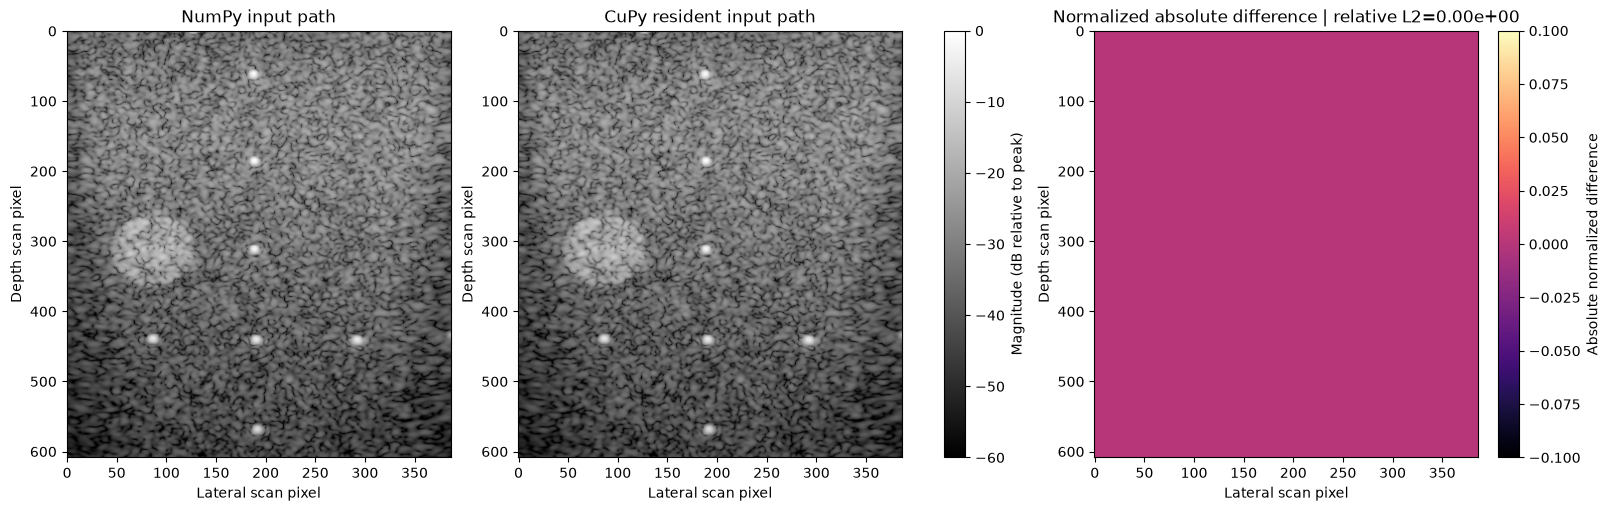

In [6]:
eps = np.finfo(np.float64).tiny
numpy_db = 20 * np.log10(np.maximum(numpy_norm, eps))
cupy_db = 20 * np.log10(np.maximum(cupy_norm, eps))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, image, title in [
    (axes[0], numpy_db, "NumPy input path"),
    (axes[1], cupy_db, "CuPy resident input path"),
]:
    artist = ax.imshow(image.T, cmap="gray", vmin=-60, vmax=0, aspect="auto", origin="upper")
    ax.set_title(title)
    ax.set_xlabel("Lateral scan pixel")
    ax.set_ylabel("Depth scan pixel")
fig.colorbar(artist, ax=axes[:2], label="Magnitude (dB relative to peak)")
err = axes[2].imshow(np.abs(difference).T, cmap="magma", aspect="auto", origin="upper")
axes[2].set_title(f"Normalized absolute difference | relative L2={relative_l2:.2e}")
axes[2].set_xlabel("Lateral scan pixel")
axes[2].set_ylabel("Depth scan pixel")
fig.colorbar(err, ax=axes[2], label="Absolute normalized difference")
fig.savefig(RESULTS / "exercise3-picmus-image-comparison.png", dpi=180)
plt.show()

## 4. Compare reported timings

The first panel separates host wall time from CUDA-event time for repeated reconstruction calls. Wall time is the user-visible duration of a beamformer call. CUDA-event time measures work ordered on the CUDA stream between recorded events; on the NumPy path, use the trace to determine whether input copies occur inside this interval.

The second panel shows one-time dataset/setup, initial CuPy upload, and final output transfer. NumPy's one-time upload field is zero; its four host arrays are staged to CuPy inside each measured call. The final-image DtoH value is measured once after the last reconstruction, not as a percentile. Both modes return a CuPy result and use the same `cp.asnumpy()` plus device synchronization to copy the same 1.885 MB image. The recorded 0.694 ms (NumPy) and 0.903 ms (CuPy) values are a one-off spread; treat them as timing variation, not evidence that NumPy has a faster output path. The Nsight screenshots show the actual final DtoH copy events at 149.470 µs and 151.422 µs, respectively, which are nearly equal.


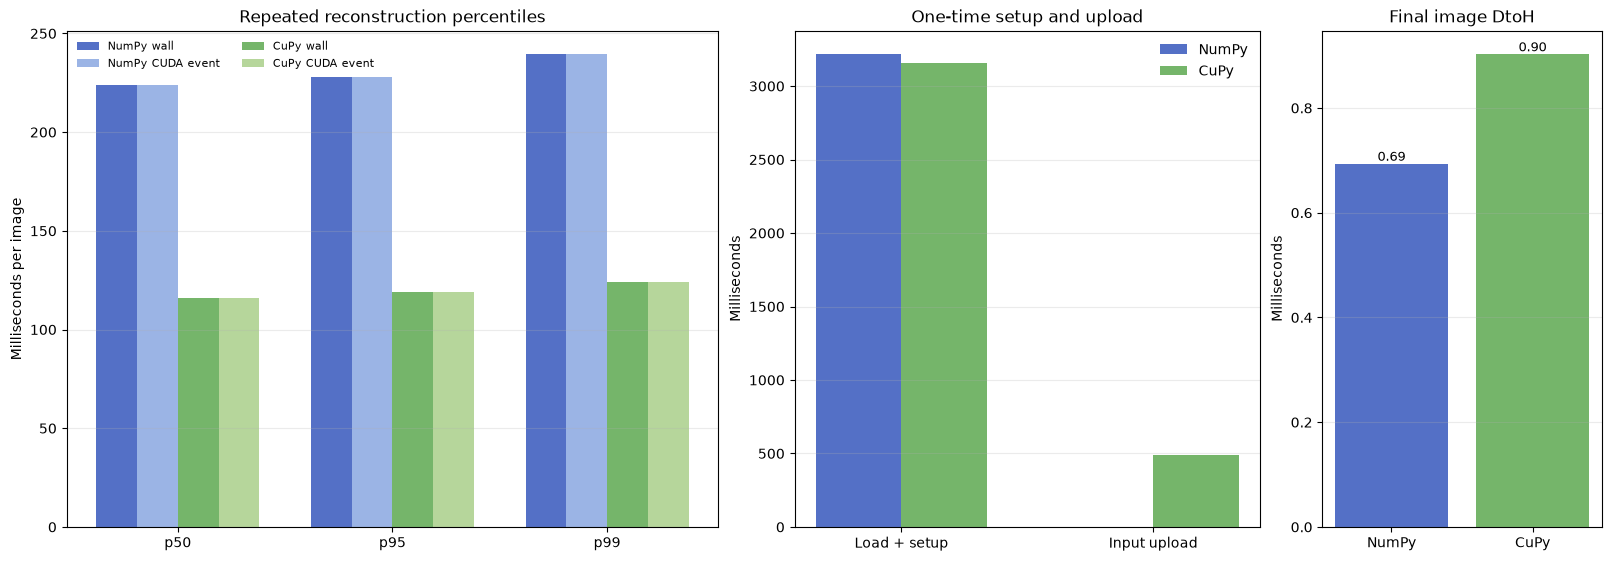

numpy: wall p50/p95/p99 = 223.777/228.059/239.424 ms; CUDA-event p50/p95/p99 = 223.756/228.035/239.398 ms; setup=3216.2 ms, input upload=0.0 ms, final output transfer=0.694 ms
cupy: wall p50/p95/p99 = 116.091/119.218/123.929 ms; CUDA-event p50/p95/p99 = 116.061/119.198/123.902 ms; setup=3157.3 ms, input upload=490.3 ms, final output transfer=0.903 ms


In [7]:
def pct(report, field, percentile):
    distribution = report[field]
    return distribution[percentile] if distribution is not None else np.nan

modes = ["numpy", "cupy"]
colors = {"numpy": "#5470c6", "cupy": "#75b56a"}
percentiles = ["p50", "p95", "p99"]
x = np.arange(len(percentiles))
width = 0.19
fig, (ax_run, ax_once, ax_output) = plt.subplots(
    1, 3, figsize=(16, 5.5), constrained_layout=True,
    gridspec_kw={"width_ratios": [2.1, 1.5, 0.9]},
)

series = [
    ("NumPy wall", "numpy", "coherent_compounding_wall_ms", colors["numpy"]),
    ("NumPy CUDA event", "numpy", "beamform_device_event_ms", "#9bb4e5"),
    ("CuPy wall", "cupy", "coherent_compounding_wall_ms", colors["cupy"]),
    ("CuPy CUDA event", "cupy", "beamform_device_event_ms", "#b6d69b"),
]
for index, (label, mode, field, color) in enumerate(series):
    offset = (index - 1.5) * width
    values = [pct(reports[mode], field, percentile) for percentile in percentiles]
    ax_run.bar(x + offset, values, width, label=label, color=color)
ax_run.set_xticks(x, percentiles)
ax_run.set_ylabel("Milliseconds per image")
ax_run.set_title("Repeated reconstruction percentiles")
ax_run.legend(fontsize=8, ncols=2, frameon=False)
ax_run.grid(axis="y", alpha=0.25)

stage_labels = ["Load + setup", "Input upload"]
stage_values = {
    mode: [
        reports[mode]["dataset_load_and_setup_ms_once"],
        reports[mode]["input_upload_ms_once"],
    ]
    for mode in modes
}
stage_x = np.arange(len(stage_labels))
stage_width = 0.34
ax_once.bar(stage_x - stage_width / 2, stage_values["numpy"], stage_width,
            label="NumPy", color=colors["numpy"])
ax_once.bar(stage_x + stage_width / 2, stage_values["cupy"], stage_width,
            label="CuPy", color=colors["cupy"])
ax_once.set_xticks(stage_x, stage_labels)
ax_once.set_ylabel("Milliseconds")
ax_once.set_title("One-time setup and upload")
ax_once.legend(frameon=False)
ax_once.grid(axis="y", alpha=0.25)

output_values = [reports[mode]["output_bmode_transfer_ms_last_run"] for mode in modes]
ax_output.bar(["NumPy", "CuPy"], output_values,
              color=[colors["numpy"], colors["cupy"]])
ax_output.set_ylabel("Milliseconds")
ax_output.set_title("Final image DtoH")
ax_output.grid(axis="y", alpha=0.25)
for index, value in enumerate(output_values):
    ax_output.text(index, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)

fig.savefig(RESULTS / "exercise3-picmus-latency-comparison.png", dpi=180)
plt.show()

for mode in modes:
    report = reports[mode]
    wall = report["coherent_compounding_wall_ms"]
    event = report["beamform_device_event_ms"]
    print(
        f"{mode}: wall p50/p95/p99 = "
        f"{wall['p50']:.3f}/{wall['p95']:.3f}/{wall['p99']:.3f} ms; "
        f"CUDA-event p50/p95/p99 = "
        f"{event['p50']:.3f}/{event['p95']:.3f}/{event['p99']:.3f} ms; "
        f"setup={report['dataset_load_and_setup_ms_once']:.1f} ms, "
        f"input upload={report['input_upload_ms_once']:.1f} ms, "
        f"final output transfer={report['output_bmode_transfer_ms_last_run']:.3f} ms"
    )

### Estimate the repeated-run break-even

If CuPy has a lower p50 wall time per reconstruction, this simple estimate divides its extra one-time input upload by the per-image wall-time savings. It omits setup costs shared by both modes and is an approximate comparison for this recorded workload.


In [8]:
numpy_wall_p50 = reports["numpy"]["coherent_compounding_wall_ms"]["p50"]
cupy_wall_p50 = reports["cupy"]["coherent_compounding_wall_ms"]["p50"]
extra_upload_ms = max(
    0.0, reports["cupy"]["input_upload_ms_once"] - reports["numpy"]["input_upload_ms_once"]
)
per_image_saving_ms = numpy_wall_p50 - cupy_wall_p50
if per_image_saving_ms > 0:
    break_even_images = int(np.ceil(extra_upload_ms / per_image_saving_ms))
    print(f"Approximate break-even: {break_even_images} reconstructed images")
else:
    print("CuPy did not have a lower wall-time p50 here; this comparison has no positive break-even estimate.")


Approximate break-even: 5 reconstructed images


### Read the timing diagram

This diagram shows data lifetime and stage ordering, not measured durations. Boxes are intentionally not drawn to scale. The Nsight question is whether the trace confirms the expected movement: repeated host-array transfers for NumPy, one initial four-array upload for CuPy, common GPU beamforming/compounding, and one final image transfer.


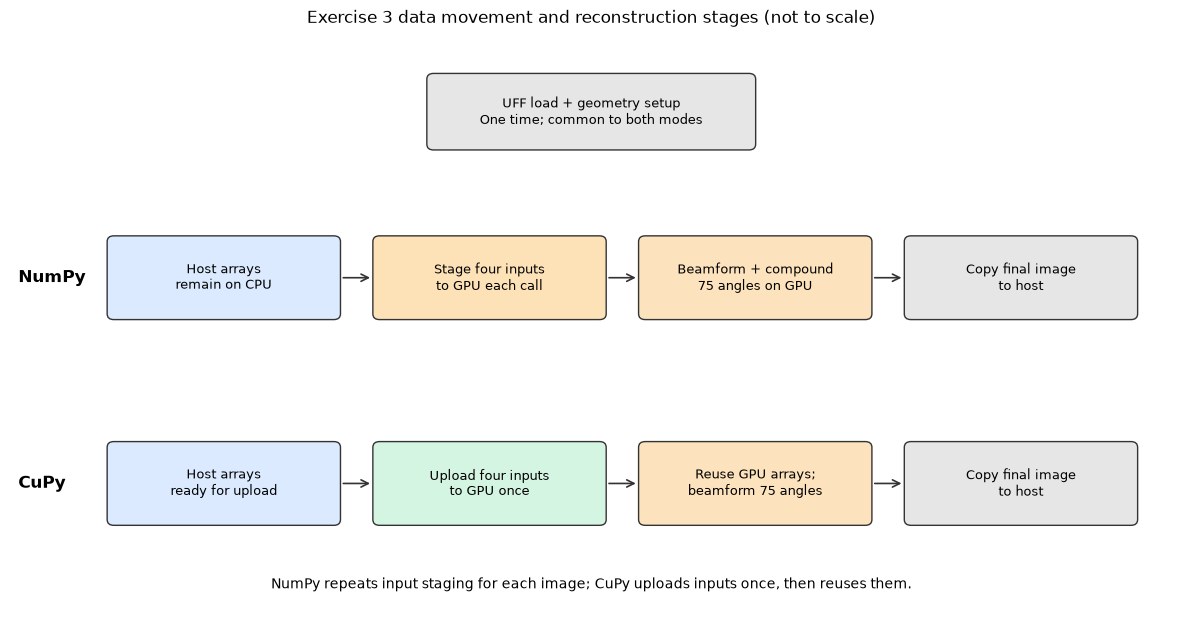

In [9]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis("off")

def box(x, y, width, height, label, color):
    patch = FancyBboxPatch(
        (x, y), width, height, boxstyle="round,pad=0.08",
        facecolor=color, edgecolor="#333333",
    )
    ax.add_patch(patch)
    ax.text(x + width / 2, y + height / 2, label,
            ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="->", mutation_scale=13,
        color="#333333", linewidth=1.2,
    ))

box(5.1, 6.55, 3.8, 0.9,
    "UFF load + geometry setup\nOne time; common to both modes", "#e6e6e6")

xs = [1.25, 4.45, 7.65, 10.85]
width = 2.65
height = 1.0
rows = [
    (4.2, "NumPy", [
        ("Host arrays\nremain on CPU", "#dbeafe"),
        ("Stage four inputs\nto GPU each call", "#fde2b8"),
        ("Beamform + compound\n75 angles on GPU", "#fce3bd"),
        ("Copy final image\nto host", "#e6e6e6"),
    ]),
    (1.35, "CuPy", [
        ("Host arrays\nready for upload", "#dbeafe"),
        ("Upload four inputs\nto GPU once", "#d5f5e3"),
        ("Reuse GPU arrays;\nbeamform 75 angles", "#fce3bd"),
        ("Copy final image\nto host", "#e6e6e6"),
    ]),
]
for y, row_label, stages in rows:
    ax.text(0.1, y + height / 2, row_label,
            fontsize=12, fontweight="bold", va="center")
    for index, (label, color) in enumerate(stages):
        box(xs[index], y, width, height, label, color)
        if index < len(stages) - 1:
            arrow(xs[index] + width + 0.08, y + height / 2,
                  xs[index + 1] - 0.08, y + height / 2)

ax.text(7, 0.45,
        "NumPy repeats input staging for each image; CuPy uploads inputs once, then reuses them.",
        ha="center", va="center", fontsize=10)
ax.set_title("Exercise 3 data movement and reconstruction stages (not to scale)", pad=12)
fig.savefig(RESULTS / "exercise3-picmus-data-lifetime.png", dpi=180)
plt.show()

## 5. Reuse or capture short Nsight Systems traces

The saved traces contain NVTX ranges named setup/dataset_load_and_geometry, setup/input_upload, warmup/beamform/(numpy or cupy), measure/beamform/(numpy or cupy), and output/bmode_d2h. They were captured with one warmup and three measured calls. In local mode, the next cell verifies the downloaded `.nsys-rep` files; in GPU mode it captures fresh traces.

In [10]:
import shutil

if RUN_BENCHMARKS:
    nsys = shutil.which("nsys")
    if nsys is None:
        raise RuntimeError("Nsight Systems CLI is not installed in the GPU runtime; install or expose nsys.")
    version = subprocess.run([nsys, "--version"], text=True, capture_output=True, check=True)
    print(version.stdout.strip() or version.stderr.strip())

    def capture_trace(mode):
        prefix = ARTIFACTS / f"exercise3-picmus-{mode}"
        command = [
            nsys, "profile", "--force-overwrite=true",
            "--trace=cuda,nvtx,osrt", "--sample=none", "--cpuctxsw=none",
            f"--output={prefix}",
            "beamform-lab", "benchmark", "--dataset", "picmus",
            "--mode", mode, "--runs", "3", "--warmup", "1", "--nvtx",
        ]
        print("Capturing:", " ".join(command))
        subprocess.run(command, cwd=REPO_ROOT, check=True)
        return Path(f"{prefix}.nsys-rep")

    numpy_trace = capture_trace("numpy")
    cupy_trace = capture_trace("cupy")
else:
    numpy_trace = ARTIFACTS / "exercise3-picmus-numpy.nsys-rep"
    cupy_trace = ARTIFACTS / "exercise3-picmus-cupy.nsys-rep"
    missing_traces = [str(p) for p in (numpy_trace, cupy_trace) if not p.is_file()]
    if missing_traces:
        raise FileNotFoundError("Saved Nsight traces are missing: " + ", ".join(missing_traces))
    print("Reusing the saved Nsight Systems traces.")

for trace in (numpy_trace, cupy_trace):
    print(f"{trace.name}: {trace.stat().st_size:,} bytes")

Reusing the saved Nsight Systems traces.
exercise3-picmus-numpy.nsys-rep: 496,043 bytes
exercise3-picmus-cupy.nsys-rep: 484,104 bytes


### Captured T4 timeline screenshots

The NumPy view shows repeated host-to-device copies inside the measured ranges alongside the 75 per-transmit `beamformKernel` launches. Its Events View reports the final `output/bmode_d2h` copy at 149.470 µs.

![Nsight Systems timeline for the NumPy-input PICMUS compounding trace](../results/exercise3-picmus-nsys-numpy.png)

The CuPy view shows the bulk input upload under `setup/input_upload`, no HtoD activity in the selected measured range, and the same 75 beamform launches. Its final `output/bmode_d2h` copy is 151.422 µs.

![Nsight Systems timeline for the CuPy-resident PICMUS compounding trace](../results/exercise3-picmus-nsys-cupy.png)

The trace findings and screenshots are summarized below in this notebook. NVTX ranges label host-side scopes and correlate with GPU operations; they do not by themselves measure only GPU execution. Keep the `.nsys-rep` files under `artifacts/` for later inspection; they are ignored by Git.

## Takeaways from the recorded T4 run

- **Image agreement:** The normalized B-mode images matched exactly in this run: relative L2 error and maximum absolute error were both `0.0`. Both show the same PICMUS phantom structures.
- **Repeated reconstruction time:** Across 20 unprofiled reconstructions, NumPy p50/p95/p99 wall time was 223.777/228.059/239.424 ms; CuPy was 116.091/119.218/123.929 ms. CUDA-event percentiles closely tracked wall time in both modes.
- **Upload break-even:** CuPy's one-time input upload took 490.259 ms and its p50 saving was 107.685 ms per image, for an approximate break-even of five images. Dataset loading and geometry setup took about 3.2 s in either mode and are reported separately.
- **Nsight copy pattern:** In the first measured NumPy range, four HtoD copies moved about 399.83 MB and took 64.86 ms. Across the full trace (one warmup plus three measured calls), NumPy made 16 HtoD copies totaling 1,599.32 MB. CuPy made four HtoD copies totaling about 399.83 MB in the one-time upload and none in the first measured range. Both traces show 75 `beamformKernel` launches per reconstruction and a final 1.885 MB DtoH image copy.
- **Scope:** This is single-frame reconstruction timing, not live acquisition-to-display latency. It does not include RF-to-IQ conversion, a streaming queue, or Power Doppler reduction. The NumPy path stages host arrays to CuPy per call because `mach-beamform 0.2.1` rejects the mixed NumPy-input/CuPy-output combination.

See the [NumPy benchmark report](../results/exercise3-picmus-numpy.json), [CuPy benchmark report](../results/exercise3-picmus-cupy.json), [NumPy trace](../artifacts/exercise3-picmus-numpy.nsys-rep), and [CuPy trace](../artifacts/exercise3-picmus-cupy.nsys-rep).